In [138]:
# =========================================================================
# Task 1 : Data Cleaning & Preparation
# =========================================================================

In [139]:
# 1. Import NumPy and Pandas libraries
import numpy as np
import pandas as pd

In [140]:
# 2. Load the dataset
df = pd.read_csv("porsche_stock_data.csv")

In [141]:
# 3. Convert date column to datetime and sort chronologically
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

In [142]:
# 4. Check and report missing values / zero-volume rows
print(f"Total rows: {len(df)}")
print(f"Missing values:\n{df.isnull().sum()}")
zero_vol_count = (df["volume"] == 0).sum()
print(
    f"Number of zero-volume days: {zero_vol_count} ( kept for time-series continuity )")

Total rows: 866
Missing values:
date      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64
Number of zero-volume days: 58 ( kept for time-series continuity )


In [143]:
# 5. Feature Engineering for Financial Analysis
# Daily Returns (%)
df["daily_return"] = df["close"].pct_change() * 100

In [144]:
# 6. Moving Averages (20-day and 50-day)
df["ma_20"] = df["close"].rolling(window=20).mean()
df["ma_50"] = df["close"].rolling(window=50).mean()

In [145]:
# 7. Rolling Volatility (20-day rolling standard deviation of daily returns)
df["volatility_20"] = df["daily_return"].rolling(window=20).std()

In [146]:
# 8. Inspect the first few rows of our cleaned & enriched dataset
print("\nCleaned Data Preview:")
print(df[["date", "close", "volume", "daily_return", "ma_20"]].head(10))


Cleaned Data Preview:
        date      close   volume  daily_return  ma_20
0 2022-09-30  75.252548  5079137           NaN    NaN
1 2022-10-03  74.614044  2403446     -0.848482    NaN
2 2022-10-04  79.795067  1599630      6.943763    NaN
3 2022-10-05  80.196411  1321304      0.502969    NaN
4 2022-10-06  82.750435  2217065      3.184711    NaN
5 2022-10-07  84.027458   880174      1.543222    NaN
6 2022-10-10  79.630882   846094     -5.232309    NaN
7 2022-10-11  76.255920  1123986     -4.238258    NaN
8 2022-10-12  79.211281  9901667      3.875582    NaN
9 2022-10-13  79.010628   428569     -0.253314    NaN


In [147]:
# 9. Save the cleaned dataset for future tasks (Power BI / Modeling)
df.to_csv("porsche_stock_cleaned.csv", index=False)
print("\nCleaned data successfully saved to 'porsche_stock_cleaned.csv'!")


Cleaned data successfully saved to 'porsche_stock_cleaned.csv'!


In [148]:
# =========================================================================
# Task 2 : Python Script for Task 2 (EDA & Visualization)
# =========================================================================

In [149]:
# 1. Import necessary libraries for visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [150]:
# 2. Load data
df = pd.read_csv("porsche_stock_data.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

In [151]:
# 3. Re-calculate features
df["daily_return"] = df["close"].pct_change() * 100
df["ma_20"] = df["close"].rolling(window=20).mean()
df["ma_50"] = df["close"].rolling(window=50).mean()
df["volatility_20"] = df["daily_return"].rolling(window=20).std()

In [152]:
# 4. Print Summary Statistics
print("--- Summary Statistics ---")
print(df[["close", "volume", "daily_return", "volatility_20"]].describe())

max_row = df.loc[df["close"].idxmax()]
min_row = df.loc[df["close"].idxmin()]
print(
    f"\nHighest Close: {max_row['close']:.2f} on {max_row['date'].strftime('%Y-%m-%d')}"
)
print(
    f"Lowest Close: {min_row['close']:.2f} on {min_row['date'].strftime('%Y-%m-%d')}"
)

--- Summary Statistics ---
            close        volume  daily_return  volatility_20
count  866.000000  8.660000e+02    865.000000     846.000000
mean    70.532747  5.674776e+05     -0.051449       1.812701
std     21.899780  5.673197e+05      1.892452       0.491757
min     39.529999  0.000000e+00     -7.152405       0.621166
25%     46.809999  3.100342e+05     -1.042757       1.443378
50%     68.686703  4.584455e+05      0.000000       1.767747
75%     88.216194  6.722385e+05      0.913662       2.184917
max    109.777496  9.901667e+06     11.469712       3.174908

Highest Close: 109.78 on 2023-05-22
Lowest Close: 39.53 on 2026-02-09


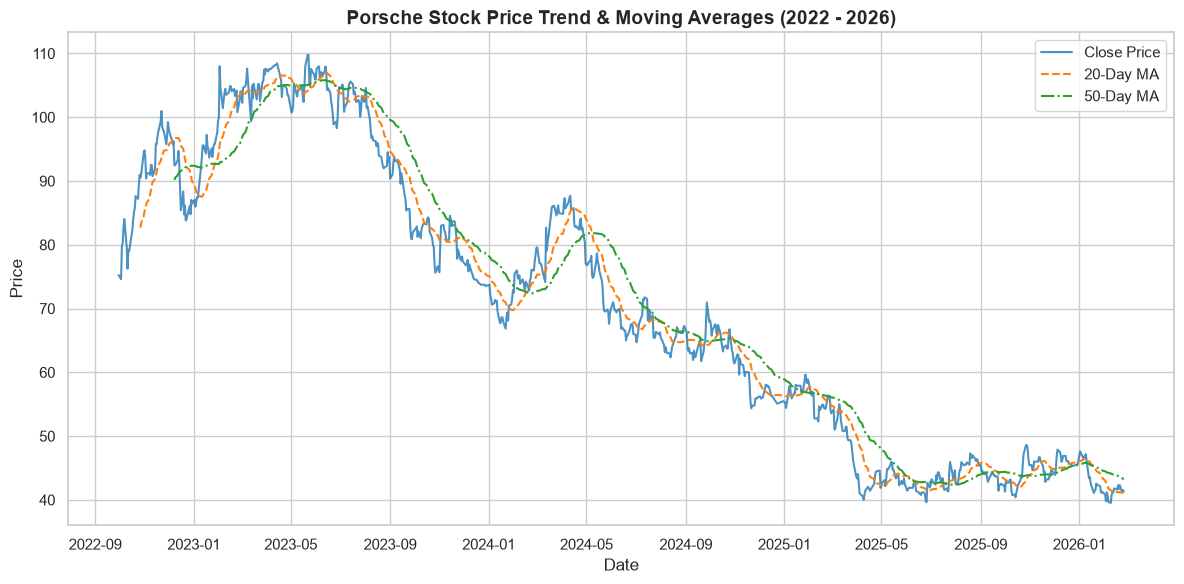

In [153]:
# 5. Generate Trend Visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

plt.plot(
    df["date"],
    df["close"],
    label="Close Price",
    color="#1f77b4",
    alpha=0.8,
)
plt.plot(
    df["date"],
    df["ma_20"],
    label="20-Day MA",
    color="#ff7f0e",
    linestyle="--",
)
plt.plot(
    df["date"],
    df["ma_50"],
    label="50-Day MA",
    color="#2ca02c",
    linestyle="-.",
)

plt.title(
    "Porsche Stock Price Trend & Moving Averages (2022 - 2026)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.legend(loc="upper right")
plt.tight_layout()

plt.savefig("porsche_trend_eda.png", dpi=300)
plt.show()

In [154]:
# =========================================================================
# Task 3: Data Visualization!
# Writing a Python script that generates these two new visual charts (Trading Volume Over Time and Price Distribution Histogram) and saves them for our project report or Power BI/Tableau prep.
# =========================================================================

In [155]:
# 1. Import necessary libraries for visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [156]:
# 1. Load data
df = pd.read_csv("porsche_stock_data.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

In [157]:
# 2. Set style
sns.set_theme(style="whitegrid")

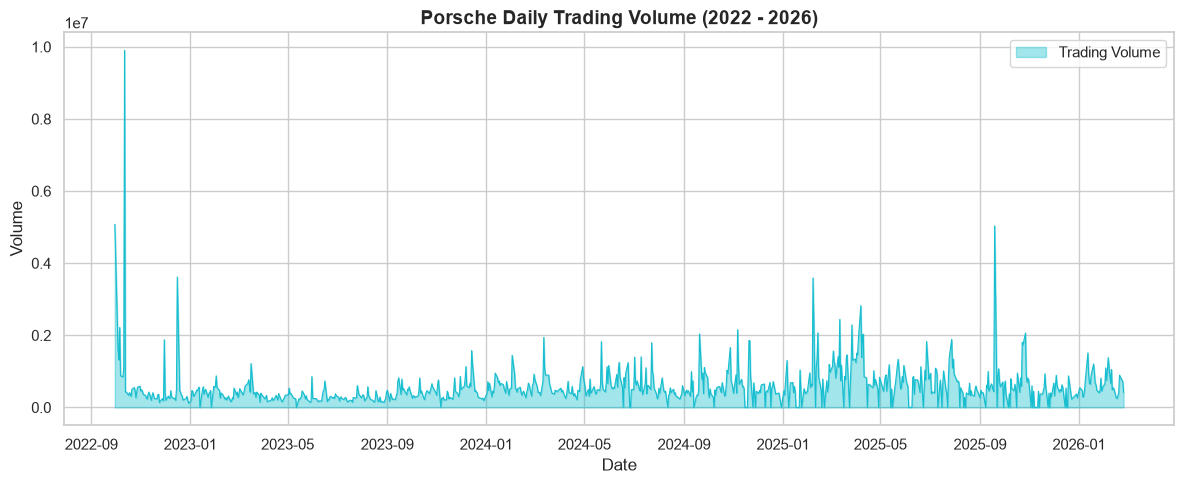

In [158]:
# --- Chart 1: Trading Volume Over Time (Bar/Area style) ---
plt.figure(figsize=(12, 5))
plt.fill_between(
    df["date"], df["volume"], color="#17becf", alpha=0.4, label="Trading Volume"
)
plt.plot(df["date"], df["volume"], color="#17becf", linewidth=0.8)
plt.title(
    "Porsche Daily Trading Volume (2022 - 2026)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Volume", fontsize=12)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("porsche_volume_chart.png", dpi=300)
plt.show()

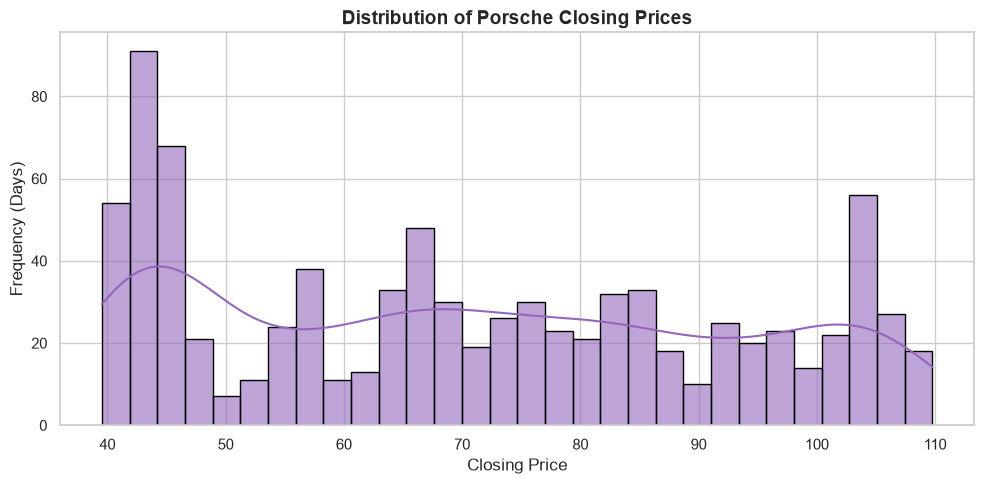

Task 3 visualizations generated and saved successfully!


In [159]:
# --- Chart 2: Closing Price Distribution (Histogram & KDE) ---
plt.figure(figsize=(10, 5))
sns.histplot(
    df["close"],
    bins=30,
    kde=True,
    color="#9467bd",
    edgecolor="black",
    alpha=0.6,
)
plt.title(
    "Distribution of Porsche Closing Prices", fontsize=14, fontweight="bold"
)
plt.xlabel("Closing Price", fontsize=12)
plt.ylabel("Frequency (Days)", fontsize=12)
plt.tight_layout()
plt.savefig("porsche_price_distribution.png", dpi=300)
plt.show()

print("Task 3 visualizations generated and saved successfully!")

In [160]:
# =========================================================================
# Task 4: Forecasting
# =========================================================================
%pip install statsmodels


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [161]:
# 1. Import necessary libraries for forecasting
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

In [162]:
# 2. Load data and set date index with business frequency
df = pd.read_csv("porsche_stock_data.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Set date as index and ensure business day frequency
ts_df = df.set_index("date")["close"].asfreq("B", method="ffill")

In [163]:
# 3. Fit the ARIMA model
model = ARIMA(ts_df, order=(1, 1, 1))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  close   No. Observations:                  889
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1515.193
Date:                Sat, 31 Oct 2026   AIC                           3036.386
Time:                        09:17:19   BIC                           3050.753
Sample:                    09-30-2022   HQIC                          3041.878
                         - 02-25-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4007      0.486      0.825      0.409      -0.551       1.352
ma.L1         -0.4410      0.477     -0.925      0.355      -1.376       0.494
sigma2         1.7766      0.048     37.385      0.0

In [164]:
# 4. Forecast future prices (next 30 business days)
forecast_steps = 30
forecast_result = model_fit.get_forecast(steps=forecast_steps)
forecast_mean = forecast_result.predicted_mean
forecast_ci = forecast_result.conf_int()

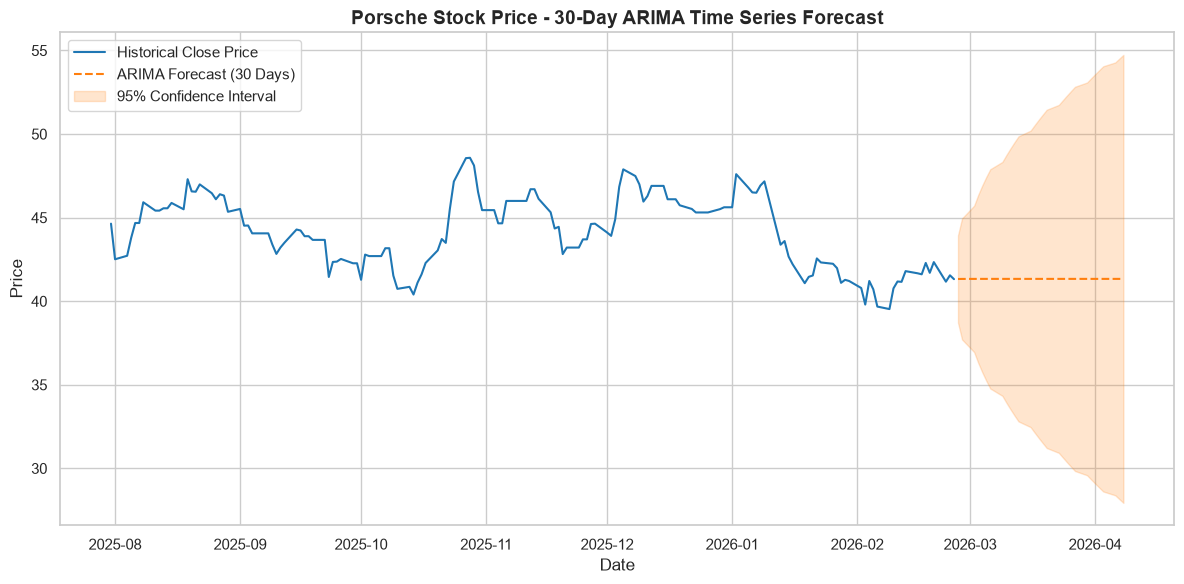

Task 4 forecasting complete and plot saved successfully!


In [165]:
# 5. Plotting Historical Data & Forecast
plt.figure(figsize=(12, 6))

zoom_history = ts_df.tail(150)
plt.plot(
    zoom_history.index,
    zoom_history,
    label="Historical Close Price",
    color="#1f77b4",
)
plt.plot(
    forecast_mean.index,
    forecast_mean,
    label="ARIMA Forecast (30 Days)",
    color="#ff7f0e",
    linestyle="--",
)

plt.fill_between(
    forecast_mean.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    color="#ff7f0e",
    alpha=0.2,
    label="95% Confidence Interval",
)

plt.title(
    "Porsche Stock Price - 30-Day ARIMA Time Series Forecast",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.legend(loc="upper left")
plt.tight_layout()

plt.savefig("porsche_arima_forecast.png", dpi=300)
plt.show()

print("Task 4 forecasting complete and plot saved successfully!")